# S4 · Construction and validation of Social Rank

Social Rank is PageRank on the signed popularity network, with weights
$a_{ij} = P^+_{ij} - P^-_{ij} + 1$ (see `code/01_build_measures.R`).
This notebook documents that coding, compares it with alternative
constructions, and relates it to other student characteristics. Code:
`code/si/S4_social_rank.R`.

In [ ]:
here::i_am("notebooks/si/S4_social_rank.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(igraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

rescale_01 <- function(x) (x - min(x)) / (max(x) - min(x))
z_score    <- function(x) if (sd(x) > 0) (x - mean(x)) / sd(x) else x * 0

## Table S7. Coding of the popularity nominations

In [ ]:
# Table S7: how each combination of the two popularity questions is coded
table_s7 <- dyads %>%
  count(positive = nom_q4, negative = nom_q5) %>%
  mutate(signed_score = positive - negative,
         weight       = signed_score + 1)

table_s7

positive,negative,n,signed_score,weight
0,0,13747,0,1
0,1,1788,-1,0
1,0,2148,1,2
1,1,121,0,1


The $+1$ shift adds the same constant ($N-1$) to every child’s incoming
weight, so before PageRank the ordering is exactly the ordering by net
nominations:

In [ ]:
# The +1 shift adds the same constant (N - 1) to every child's incoming
# weight, so ranking by incoming weight = ranking by net nominations q_j.
check_shift <- dyads %>%
  group_by(class_id, receiver_id) %>%
  summarise(incoming_weight = sum(nom_q4 - nom_q5 + 1),
            net_nominations = sum(nom_q4) - sum(nom_q5),
            n_minus_1       = n(), .groups = "drop")

all(check_shift$incoming_weight == check_shift$n_minus_1 + check_shift$net_nominations)
## [1] TRUE

## Alternative constructions (Table S8)

In [ ]:
# PageRank of every child in one classroom, for any choice of edge weights.
# Edges with weight 0 are dropped (igraph does not accept them as "no edge"
# otherwise); children without incoming edges keep the teleport share.
pagerank_weights <- function(edges) {
  children <- unique(c(edges$from, edges$to))
  network <- graph_from_data_frame(edges %>% filter(weight > 0),
                                   vertices = data.frame(name = children))
  pr <- page_rank(network, damping = 0.85, directed = TRUE)$vector
  tibble(student_id = as.numeric(names(pr)), value = pr)
}

pagerank_by_class <- function(weight_formula) {
  dyads %>%
    transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id),
              weight = {{ weight_formula }}) %>%
    group_by(class_id) %>%
    group_modify(~ pagerank_weights(.x)) %>%
    ungroup()
}

In [ ]:
# Alternatives (Table S8). Every score is oriented so that higher = higher
# standing and rescaled 0-1 within classroom.

in_degrees <- dyads %>%
  group_by(class_id, student_id = receiver_id) %>%
  summarise(positive_in = sum(nom_q4), negative_in = sum(nom_q5), .groups = "drop")

pr_positive <- pagerank_by_class(nom_q4) %>% rename(pr_positive = value)
pr_negative <- pagerank_by_class(nom_q5) %>% rename(pr_negative = value)

# Signed in-PN centrality (Everett and Borgatti 2014), on the signed network
# A = P+ - 2 P-, computed for incoming ties: PN = (I - A' / (2n - 2))^-1 1
pn_centrality <- function(class_dyads) {
  ids <- sort(unique(class_dyads$sender_id))
  n <- length(ids)
  A <- matrix(0, n, n, dimnames = list(ids, ids))
  A[cbind(as.character(class_dyads$sender_id), as.character(class_dyads$receiver_id))] <-
    class_dyads$nom_q4 - 2 * class_dyads$nom_q5
  pn <- solve(diag(n) - t(A) / (2 * n - 2), rep(1, n))
  tibble(student_id = ids, pn_in = as.numeric(pn))
}

pn_scores <- dyads %>% group_by(class_id) %>% group_modify(~ pn_centrality(.x)) %>% ungroup()

alternative_ranks <- students %>%
  select(student_id, class_id, social_rank) %>%
  left_join(in_degrees,  by = c("class_id", "student_id")) %>%
  left_join(pr_positive, by = c("class_id", "student_id")) %>%
  left_join(pr_negative, by = c("class_id", "student_id")) %>%
  left_join(pn_scores,   by = c("class_id", "student_id")) %>%
  group_by(class_id) %>%
  mutate(rank_positive_only    = rescale_01(pr_positive),
         rank_two_layer        = rescale_01(z_score(pr_positive) - z_score(pr_negative)),
         rank_net_nominations  = rescale_01(z_score(positive_in) - z_score(negative_in)),
         rank_pr_minus_neg_in  = rescale_01(z_score(pr_positive) - z_score(negative_in)),
         rank_pn_centrality    = rescale_01(pn_in)) %>%
  ungroup()

alternative_labels <- c(
  rank_net_nominations = "Net popularity nominations",
  rank_pn_centrality   = "Signed in-PN centrality",
  rank_pr_minus_neg_in = "Positive PageRank minus negative indegree",
  rank_two_layer       = "Two-layer PageRank",
  rank_positive_only   = "Positive-only PageRank"
)

## Figure S6. Agreement with the primary Social Rank

The median within-classroom Spearman correlation is the number quoted in
the SI text; the pooled correlation is plotted.

measure,pooled_spearman,median_within_class_spearman
Net popularity nominations,0.9653854,0.9805028
Signed in-PN centrality,0.9807659,0.9731801
Positive PageRank minus negative indegree,0.9065338,0.9457933
Two-layer PageRank,0.7914976,0.8800000
Positive-only PageRank,0.7345500,0.8022608


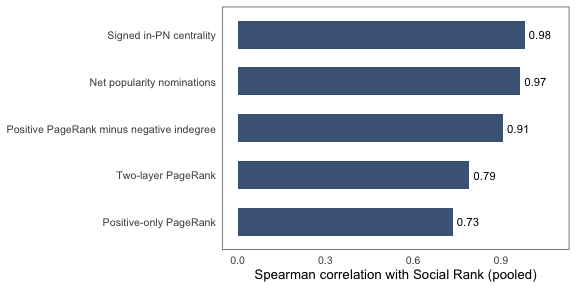

In [ ]:
# Agreement with the primary Social Rank: median within-classroom Spearman
# (reported in the text) and pooled Spearman (Figure S6)
ranks_long <- alternative_ranks %>%
  pivot_longer(all_of(names(alternative_labels)), names_to = "measure", values_to = "rank")

within_class <- ranks_long %>%
  group_by(measure, class_id) %>%
  summarise(spearman = cor(social_rank, rank, method = "spearman"), .groups = "drop") %>%
  group_by(measure) %>%
  summarise(median_within_class_spearman = median(spearman))

construction_agreement <- ranks_long %>%
  group_by(measure) %>%
  summarise(pooled_spearman = cor(social_rank, rank, method = "spearman")) %>%
  left_join(within_class, by = "measure") %>%
  mutate(measure = alternative_labels[measure]) %>%
  arrange(desc(median_within_class_spearman))

construction_agreement

## Figure S7. Weight given to non-nominations

Explicit negative = 0 and explicit positive = 2 are kept; the weight of
“not named” goes from 0 to 2. The primary measure is $w = 1$.

w,median,min
0.00,0.8022608,0.3155215
0.25,0.9226087,0.5335397
0.50,0.9616036,0.5833333
0.75,0.9841897,0.8461538
1.00,1.0000000,1.0000000
1.25,0.9853190,0.9088235
1.50,0.9523810,0.8181818
1.75,0.8919028,0.7482517
2.00,0.7921739,0.5242941


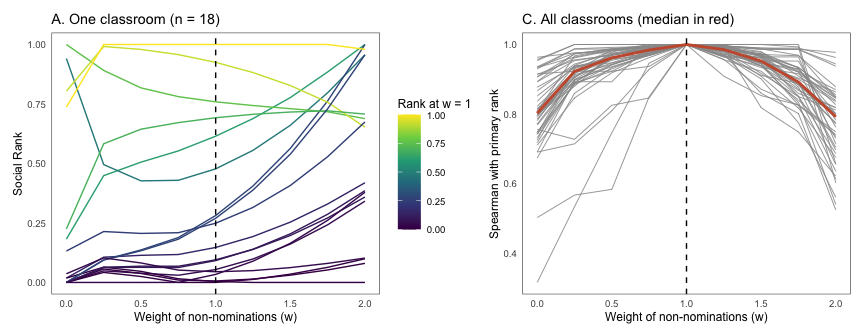

In [ ]:
# Figure S7: keep explicit negative = 0 and explicit positive = 2, and give
# non-nominations (and offsetting pairs) a weight w from 0 to 2.
# w = 1 is the primary Social Rank.
weights_to_try <- seq(0, 2, by = 0.25)

rank_with_weight <- map_dfr(weights_to_try, function(w) {
  pagerank_by_class(case_when(nom_q4 - nom_q5 ==  1 ~ 2,
                              nom_q4 - nom_q5 == -1 ~ 0,
                              TRUE                  ~ w)) %>%
    group_by(class_id) %>%
    mutate(rank = rescale_01(value), w = w) %>%
    ungroup()
})

reference_weight_agreement <- rank_with_weight %>%
  left_join(students %>% select(student_id, social_rank), by = "student_id") %>%
  group_by(w, class_id) %>%
  summarise(spearman = cor(rank, social_rank, method = "spearman"), .groups = "drop")

reference_weight_agreement %>%
  group_by(w) %>%
  summarise(median = median(spearman), min = min(spearman))

## Table S9. Social Rank and student characteristics

### Panel A. Correlations with Social Rank

The within-classroom correlations remove classroom means. Nomination
counts and continuous variables are standardized within classrooms.

In [ ]:
# Table S9, Panel A: correlations between Social Rank and other student
# characteristics. Nomination counts and continuous variables are turned into
# within-classroom z-scores. "Within-class" correlations remove the classroom
# mean of both variables first. SE = sqrt((1 - r^2) / (n - 2)).

nominations_received <- dyads %>%
  group_by(student_id = receiver_id) %>%
  summarise(across(starts_with("nom_q"), sum))

z_score_na <- function(x) (x - mean(x, na.rm = TRUE)) / sd(x, na.rm = TRUE)

correlates <- students %>%
  left_join(nominations_received, by = "student_id") %>%
  mutate(age = if_else(age > 15, NA_real_, age),
         net_popularity = nom_q4 - nom_q5) %>%
  group_by(class_id) %>%
  mutate(across(c(starts_with("nom_q"), net_popularity, attendance, gpa, age), z_score_na),
         aggression   = (nom_q6 + nom_q7) / 2,
         prosociality = (nom_q8 + nom_q9) / 2) %>%
  ungroup()

correlate_labels <- c(
  nom_q3 = "Best-friend nominations", nom_q1 = "Most-like-to-hang-out nominations",
  nom_q2 = "Least-like-to-hang-out nominations", net_popularity = "Net popularity nominations",
  nom_q4 = "Most-popular nominations (Q4)", nom_q5 = "Not-popular nominations (Q5)",
  nom_q6 = "Initiate-fights nominations (Q6)", nom_q7 = "Make-fun-of-others nominations (Q7)",
  nom_q8 = "Kind-to-others nominations (Q8)", nom_q9 = "Cooperative nominations (Q9)",
  aggression = "Aggression composite", prosociality = "Prosociality composite",
  attendance = "Attendance (within-class z)", gpa = "GPA (within-class z)",
  age = "Age (within-class z)", female = "Sex (female indicator)",
  repeated_grade = "Grade repetition (repeated indicator)"
)

correlation_row <- function(variable) {
  d <- correlates %>%
    select(class_id, social_rank, x = all_of(variable)) %>%
    filter(!is.na(x)) %>%
    group_by(class_id) %>%
    mutate(rank_within = social_rank - mean(social_rank), x_within = x - mean(x)) %>%
    ungroup()
  r <- c(pooled_pearson  = cor(d$social_rank, d$x),
         pooled_spearman = cor(d$social_rank, d$x, method = "spearman"),
         within_pearson  = cor(d$rank_within, d$x_within),
         within_spearman = cor(d$rank_within, d$x_within, method = "spearman"))
  tibble(measure = correlate_labels[[variable]], n = nrow(d),
         statistic = names(r), r = r, se = sqrt((1 - r^2) / (nrow(d) - 2)))
}

table_s9_a <- map_dfr(names(correlate_labels), correlation_row)

table_s9_a %>%
  select(measure, statistic, r) %>%
  pivot_wider(names_from = statistic, values_from = r) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))

measure,pooled_pearson,pooled_spearman,within_pearson,within_spearman
Best-friend nominations,0.495,0.458,0.527,0.498
Most-like-to-hang-out nominations,0.523,0.494,0.556,0.534
Least-like-to-hang-out nominations,-0.177,-0.159,-0.188,-0.174
Net popularity nominations,0.924,0.928,0.983,0.990
Most-popular nominations (Q4),0.806,0.769,0.858,0.842
Not-popular nominations (Q5),-0.690,-0.694,-0.735,-0.756
Initiate-fights nominations (Q6),0.194,0.176,0.207,0.180
Make-fun-of-others nominations (Q7),0.159,0.116,0.169,0.122
Kind-to-others nominations (Q8),0.277,0.249,0.295,0.270
Cooperative nominations (Q9),0.338,0.296,0.360,0.318


### Panel B. Differences by guardian education

The table reports tests for differences in Social Rank by guardian
education. The public data do not include religion.

In [ ]:
# Table S9, Panel B: does Social Rank differ by guardian education (4 levels)?
# p-values from OLS and from a model with classroom FE (clustered SE), and the
# within-classroom partial R2 of the education categories.
# (Religion is also in the SI table; it is not part of the public data.)
ols_model <- lm(social_rank ~ guardian_education, data = students)
fe_model  <- felm(social_rank ~ guardian_education | class_id | 0 | class_id,
                  data = students %>% mutate(class_id = factor(class_id)))
fe_only   <- felm(social_rank ~ 1 | class_id, data = students %>% mutate(class_id = factor(class_id)))

table_s9_b <- tibble(
  characteristic = "Guardian education (4 levels)",
  ols_p          = anova(lm(social_rank ~ 1, data = students), ols_model)$`Pr(>F)`[2],
  # joint test that all education coefficients are zero (clustered)
  fe_cluster_p   = lfe::waldtest(fe_model, seq_along(coef(fe_model)))[["p.F"]],
  partial_r2     = 1 - sum(residuals(fe_model)^2) / sum(residuals(fe_only)^2),
  n              = nrow(students)
)

table_s9_b

characteristic,ols_p,fe_cluster_p,partial_r2,n
Guardian education (4 levels),0.4460258,0.1605008,0.0087315,859


## Figure S8

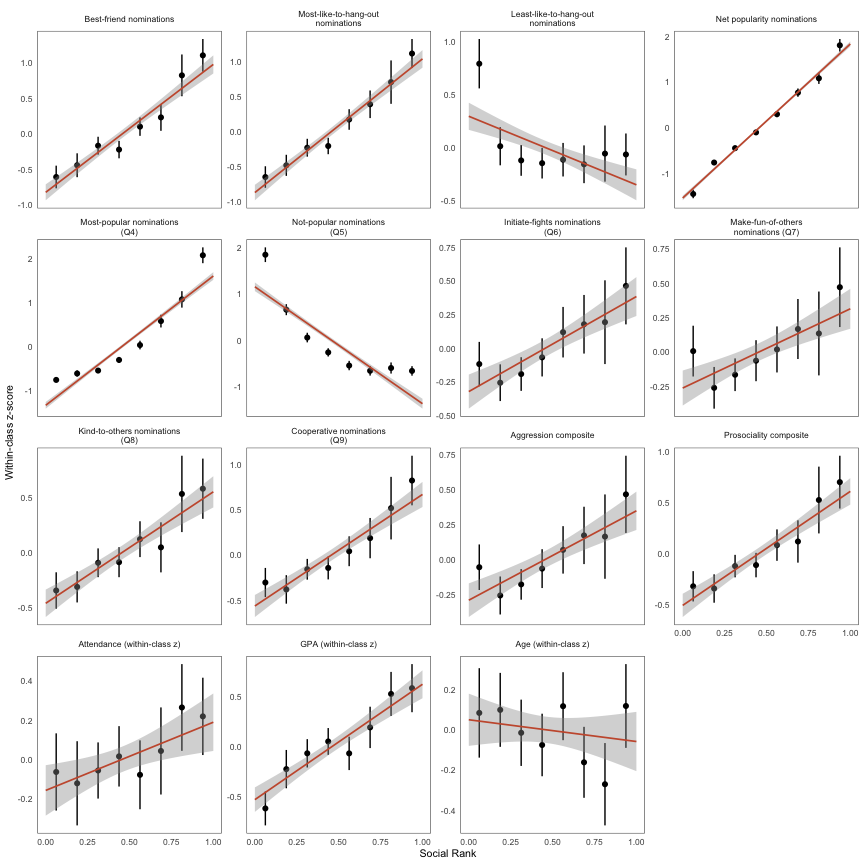

In [ ]:
# Figure S8 (continuous correlates): Social Rank against each characteristic,
# binned means with a linear fit
figure_s8 <- correlates %>%
  select(social_rank, all_of(setdiff(names(correlate_labels), c("female", "repeated_grade")))) %>%
  pivot_longer(-social_rank, names_to = "variable", values_to = "value") %>%
  filter(!is.na(value)) %>%
  mutate(variable = factor(correlate_labels[variable], levels = correlate_labels)) %>%
  ggplot(aes(social_rank, value)) +
  stat_summary_bin(fun.data = mean_cl_normal, bins = 8, size = 0.2) +
  geom_smooth(method = "lm", color = "#C95A3A", linewidth = 0.6) +
  facet_wrap(~ variable, ncol = 4, scales = "free_y",
             labeller = label_wrap_gen(width = 28)) +
  labs(x = "Social Rank", y = "Within-class z-score") +
  theme_paper(base_size = 8) +
  theme(strip.background = element_blank())

figure_s8

## Table S10. Distribution of the Social Rank GAP

In [ ]:
# Table S10: distribution of the Social Rank GAP
gap_distribution <- function(data, label) {
  tibble(sample = label, n = nrow(data), min = min(data$rank_gap),
         p10 = quantile(data$rank_gap, 0.10), p25 = quantile(data$rank_gap, 0.25),
         median = median(data$rank_gap), p75 = quantile(data$rank_gap, 0.75),
         p90 = quantile(data$rank_gap, 0.90), sd = sd(data$rank_gap))
}

table_s10 <- bind_rows(
  gap_distribution(dyads, "All directed interactions"),
  gap_distribution(filter(dyads, friendship == "Non-friends"), "Non-friends"),
  gap_distribution(filter(dyads, friendship %in% c("Sender declares", "Receiver declares")),
                   "Unilateral friendships"),
  gap_distribution(filter(dyads, friendship == "Mutual"), "Mutual friends")
)

table_s10 %>% mutate(across(where(is.double), ~ round(.x, 3)))

sample,n,min,p10,p25,median,p75,p90,sd
All directed interactions,17804,-1,-0.460,-0.221,0,0.221,0.460,0.354
Non-friends,13916,-1,-0.470,-0.222,0,0.222,0.470,0.361
Unilateral friendships,2600,-1,-0.450,-0.237,0,0.237,0.450,0.349
Mutual friends,1288,-1,-0.371,-0.180,0,0.180,0.371,0.295


In [ ]:
save_table(table_s7, "S4_table_s7_coding")
save_table(construction_agreement, "S4_construction_agreement")
save_table(table_s9_a, "S4_table_s9a_correlates")
save_table(table_s9_b, "S4_table_s9b_background")
save_table(table_s10, "S4_table_s10_gap_distribution")
write_csv(alternative_ranks, here("data", "generated", "alternative_ranks.csv"))

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}
save_si_figure(figure_s6, "S4_figure_s6_construction_correlations", 6, 3)
save_si_figure(figure_s7, "S4_figure_s7_reference_weight", 9, 3.5)
save_si_figure(figure_s8, "S4_figure_s8_correlates", 9, 9)